In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
import sys

sys.path.append("../src")

from polymap.graph import build_graph

/Users/arulnanda/Desktop/polymap/.venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [3]:
import torch
from torch_geometric.data import Data

In [4]:
temporal_edges = pd.read_parquet(
    "../data/processed/temporal_edges.parquet"
)

wallet_features = pd.read_parquet(
    "../data/processed/wallet_features.parquet"
)

In [5]:
(
    data,
    wallet_to_id,
    id_to_wallet,
    node_features_graph,
    scaler,
) = build_graph(
    temporal_edges,
    wallet_features
)

In [6]:
print(data)

Data(x=[2356, 9], edge_index=[2, 103779], edge_attr=[103779, 4], timestamp=[103779])


In [7]:
X = data.x.numpy()

print("Feature matrix:", X.shape)

Feature matrix: (2356, 9)


In [8]:
k_values = range(2, 11)

silhouette_scores = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X)

    score = silhouette_score(
        X,
        labels
    )

    silhouette_scores.append(score)

    print(
        f"K={k}: "
        f"Silhouette={score:.4f}"
    )

K=2: Silhouette=0.6541
K=3: Silhouette=0.3084
K=4: Silhouette=0.3435
K=5: Silhouette=0.3520
K=6: Silhouette=0.3686
K=7: Silhouette=0.3997
K=8: Silhouette=0.4322
K=9: Silhouette=0.4516
K=10: Silhouette=0.4746


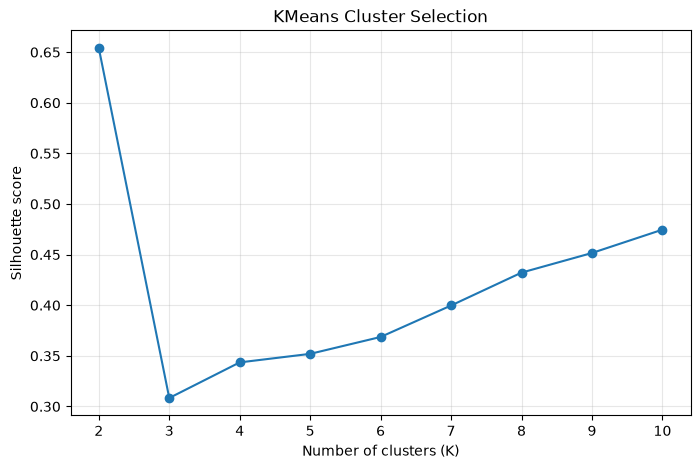

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score")
plt.title("KMeans Cluster Selection")

plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.show()

In [10]:
kmeans_2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

labels_2 = kmeans_2.fit_predict(X)

node_features_graph["cluster"] = labels_2

In [11]:
print(
    node_features_graph["cluster"]
    .value_counts()
    .sort_index()
)

cluster
0    2293
1      63
Name: count, dtype: int64


In [12]:
cluster_summary = (
    node_features_graph
    .groupby("cluster")
    .agg(
        wallets=("proxyWallet", "size"),
        avg_trades=("trade_count", "mean"),
        median_trades=("trade_count", "median"),
        avg_trade_size=("avg_trade_size", "mean"),
        median_trade_size=("median_trade_size", "mean"),
        avg_price=("avg_price", "mean"),
        avg_buy_ratio=("buy_ratio", "mean"),
        avg_sell_ratio=("sell_ratio", "mean"),
        avg_outcomes=("unique_outcomes", "mean"),
        avg_duration=("active_duration_hours", "mean"),
    )
)

cluster_summary

,wallets,avg_trades,median_trades,avg_trade_size,median_trade_size,avg_price,avg_buy_ratio,avg_sell_ratio,avg_outcomes,avg_duration
cluster,,,,,,,,,,
0,2293,3.519843,1.0,721.312709,627.585172,0.714344,0.493616,0.506384,1.0,123.563925
1,63,30.619048,9.0,393.707441,118.625552,0.580238,0.612871,0.387129,2.0,663.056354


In [13]:
for cluster in [0, 1]:

    subset = node_features_graph[
        node_features_graph["cluster"] == cluster
    ]

    print(f"\n===== CLUSTER {cluster} =====")

    print(
        subset[
            [
                "trade_count",
                "avg_trade_size",
                "buy_ratio",
                "avg_price",
                "unique_outcomes",
                "active_duration_hours"
            ]
        ].describe()
    )


===== CLUSTER 0 =====
       trade_count  avg_trade_size    buy_ratio    avg_price  unique_outcomes  \
count  2293.000000     2293.000000  2293.000000  2293.000000           2293.0   
mean      3.519843      721.312709     0.493616     0.714344              1.0   
std      22.656902     5056.846172     0.399710     0.368439              0.0   
min       1.000000        0.010000     0.000000     0.034500              1.0   
25%       1.000000        6.700000     0.000000     0.910000              1.0   
50%       1.000000       22.000000     0.500000     0.920000              1.0   
75%       2.000000      200.000000     1.000000     0.930000              1.0   
max     959.000000   195592.660000     1.000000     0.970000              1.0   

       active_duration_hours  
count            2293.000000  
mean              123.563925  
std               307.328755  
min                 0.000000  
25%                 0.000000  
50%                 0.000000  
75%                 8.053611  

In [14]:
baseline_features = [
    "log_trade_count",
    "buy_ratio",
    "sell_ratio",
    "log_avg_trade_size",
    "log_median_trade_size",
    "avg_price",
    "price_std",
    "log_active_duration"
]

In [15]:
X_baseline = (
    node_features_graph[baseline_features]
    .values
)

In [16]:
from sklearn.preprocessing import StandardScaler

baseline_scaler = StandardScaler()

X_baseline = baseline_scaler.fit_transform(
    X_baseline
)

In [17]:
k_values = range(2, 11)

baseline_scores = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_baseline)

    score = silhouette_score(
        X_baseline,
        labels
    )

    baseline_scores.append(score)

    print(
        f"K={k}: "
        f"Silhouette={score:.4f}"
    )

K=2: Silhouette=0.2979
K=3: Silhouette=0.3214
K=4: Silhouette=0.3400
K=5: Silhouette=0.3477
K=6: Silhouette=0.3651
K=7: Silhouette=0.3957
K=8: Silhouette=0.4277
K=9: Silhouette=0.4570
K=10: Silhouette=0.4719


In [18]:
kmeans_10 = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

labels_10 = kmeans_10.fit_predict(X_baseline)

node_features_graph["cluster_10"] = labels_10

In [19]:
# Save baseline cluster assignments so other notebooks can use them
node_features_graph[["proxyWallet", "cluster_10"]].to_parquet(
    "../data/processed/baseline_clusters.parquet"
)

In [20]:
print(
    node_features_graph["cluster_10"]
    .value_counts()
    .sort_index()
)

cluster_10
0    100
1    536
2    137
3    196
4    264
5    375
6    354
7     58
8    178
9    158
Name: count, dtype: int64


In [21]:
cluster_summary_10 = (
    node_features_graph
    .groupby("cluster_10")
    .agg(
        wallets=("proxyWallet", "size"),
        avg_trades=("trade_count", "mean"),
        median_trades=("trade_count", "median"),
        avg_trade_size=("avg_trade_size", "mean"),
        median_trade_size=("median_trade_size", "mean"),
        avg_price=("avg_price", "mean"),
        avg_buy_ratio=("buy_ratio", "mean"),
        avg_sell_ratio=("sell_ratio", "mean"),
        avg_price_std=("price_std", "mean"),
        avg_duration=("active_duration_hours", "mean"),
    )
    .sort_values("wallets", ascending=False)
)

cluster_summary_10

,wallets,avg_trades,median_trades,avg_trade_size,median_trade_size,avg_price,avg_buy_ratio,avg_sell_ratio,avg_price_std,avg_duration
cluster_10,,,,,,,,,,
1,536,2.281716,2.0,6.612181,6.512790,0.919784,0.499756,0.500244,6.839667e-03,70.932717
5,375,1.136000,1.0,26.074045,25.418800,0.921824,0.000000,1.000000,6.426597e-10,0.875724
6,354,1.070621,1.0,25.426269,24.671206,0.935014,1.000000,0.000000,1.997497e-05,0.382119
4,264,3.583333,3.0,904.009698,753.382278,0.550888,0.554911,0.445089,9.753932e-03,619.747140
3,196,1.525510,1.0,115.960567,108.078595,0.075522,0.861002,0.138998,1.879460e-03,4.988865
8,178,1.140449,1.0,267.760194,266.418427,0.068886,0.006742,0.993258,3.534915e-04,5.323972
9,158,1.468354,1.0,4607.509334,4231.811114,0.865098,0.017405,0.982595,5.058627e-04,31.476306
2,137,1.284672,1.0,3286.467796,3154.066948,0.742694,0.988443,0.011557,4.214446e-04,17.698339
0,100,45.700000,23.5,1477.610166,493.884535,0.619094,0.571399,0.428601,1.390919e-02,776.013903
